In [17]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

from dataset.toy import ToyDataset
from models.vae_toy import VAE

exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/2024-07-02/18-02-18"

project_dir = "/home/lagandua/projects/sven/pineapple"
model_path = f"{exp_dir}/model_29.pth"
data_name = "val_toy_4blobs"
data_path = f"{project_dir}/data/toy/{data_name}.npz"
out_dir = f"{project_dir}/exp/plots/vae-toy/"
os.makedirs(out_dir, exist_ok=True)
comment = ""
device = 'cuda:0'

In [18]:
out_dir

'/home/lagandua/projects/sven/pineapple/exp/plots/vae-toy/'

In [19]:
val_dataset = ToyDataset(data_path)
val_dataloader = torch.utils.data.DataLoader(
        val_dataset, batch_size=64, shuffle=True
    )

In [20]:
input_size = val_dataset.data.shape[-1]
latent_dim = 32
model = (
        VAE(input_size, latent_dim=latent_dim, distribution="normal")
        .to(device)
        .float()
    )
model.load_state_dict(torch.load(model_path))
model.eval()

VAE(
  (activation): ELU(alpha=1.0)
  (encoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ELU(alpha=1.0)
  )
  (fc_mu): Linear(in_features=32, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=32, out_features=32, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=32, out_features=2, bias=True)
  )
)

In [21]:
val_reps = []
val_recons = []
val_inputs = []
val_labels = []
with torch.no_grad():
    for val_input, val_target in val_dataloader:
        val_input = val_input.to(device).float()
        recon, z, _ = model(val_input)

        val_labels.extend(val_target.cpu().numpy().tolist())
        val_reps.extend(z.cpu().numpy().tolist())
        val_recons.extend(recon.cpu().numpy().tolist())
        val_inputs.extend(val_input.cpu().numpy().tolist())

In [22]:
import numpy as np
import matplotlib.pyplot as plt

val_reps = np.array(val_reps)
count = len(val_reps)

# Embeddings
embeddings = np.copy(val_reps[:count])

# Labels
# labels = np.copy(val_dataset.label_indices[:count])
labels = np.array(val_labels)

In [23]:
import umap

# Initialize UMAP model
umap_model = umap.UMAP(n_neighbors=15, n_components=2, metric='euclidean')

# Fit and transform the embeddings
umap_embeddings = umap_model.fit_transform(embeddings)

/tmp/ipykernel_395727/944747763.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  handles = [plt.scatter(umap_embeddings[labels == l, 0], umap_embeddings[labels == l, 1], s=5, c=colours[l]) for l in sorted(set(labels))]


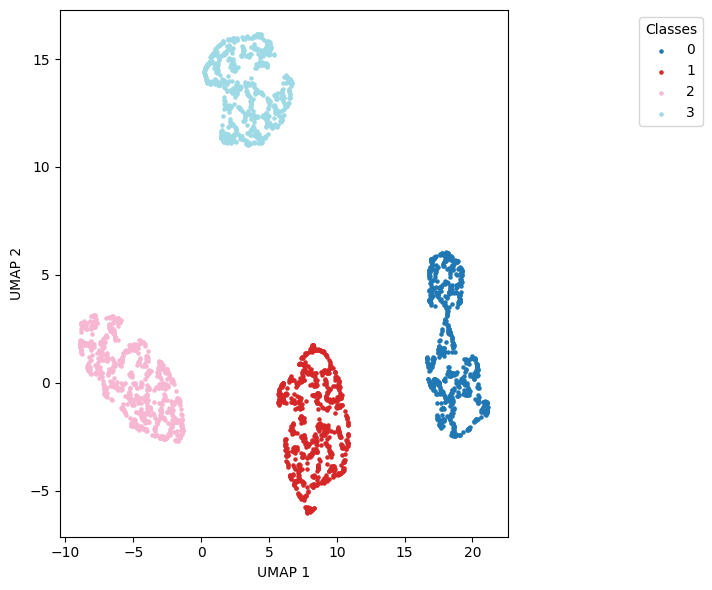

In [24]:
cmap = plt.get_cmap('tab20')
values = np.linspace(0, 1, len(set(labels)))
colours = [cmap(val) for val in values]

# Plot the UMAP results
plt.figure(figsize=(8, 6))
handles = [plt.scatter(umap_embeddings[labels == l, 0], umap_embeddings[labels == l, 1], s=5, c=colours[l]) for l in sorted(set(labels))]
custom_labels = sorted(set(labels))

# Create a legend with custom labels
plt.legend(handles, custom_labels, title="Classes", loc="upper right", bbox_to_anchor=(1.45, 1.0))

plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.tight_layout()
plt.savefig(f"{out_dir}/umap-vae-{latent_dim}-{data_name}-{comment}.png")
plt.show()


In [25]:
from sklearn.manifold import TSNE

# Perform t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(embeddings)


/tmp/ipykernel_395727/946486123.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  handles = [plt.scatter(X_embedded[labels == l, 0], X_embedded[labels == l, 1], s=5, c=colours[l]) for l in sorted(set(labels))]


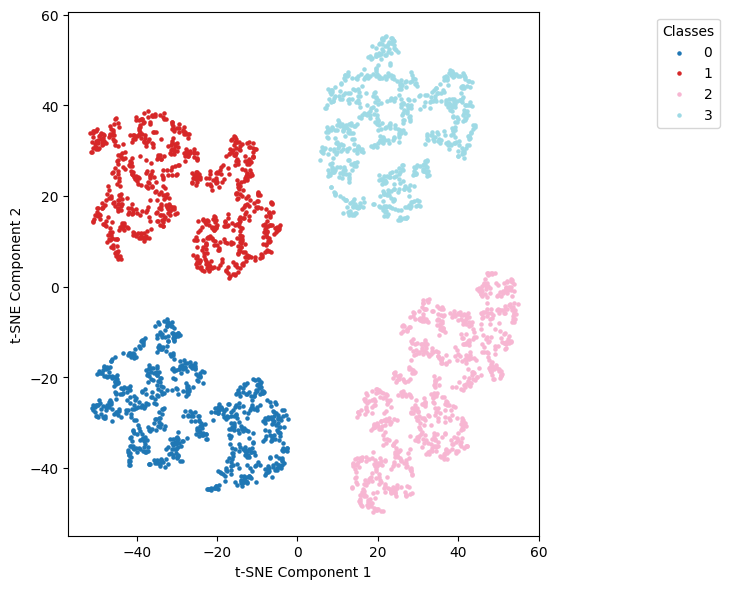

In [26]:
cmap = plt.get_cmap('tab20')
values = np.linspace(0, 1, len(set(labels)))
colours = [cmap(val) for val in values]

# Plot the UMAP results
plt.figure(figsize=(8, 6))
handles = [plt.scatter(X_embedded[labels == l, 0], X_embedded[labels == l, 1], s=5, c=colours[l]) for l in sorted(set(labels))]
custom_labels = sorted(set(labels))

# Create a legend with custom labels
plt.legend(handles, custom_labels, title="Classes", loc="upper right", bbox_to_anchor=(1.4, 1))

# Show label mappings in the title
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.tight_layout()
plt.savefig(f"{out_dir}/t-SNE-vae-{latent_dim}-{data_name}-{comment}.png")
plt.show()


### Reconstruction

In [27]:
val_recons = np.array(val_recons)

/tmp/ipykernel_395727/3122707174.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  handles = [plt.scatter(val_recons[labels == l, 0], val_recons[labels == l, 1], s=5, c=colours[l]) for l in sorted(set(labels))]


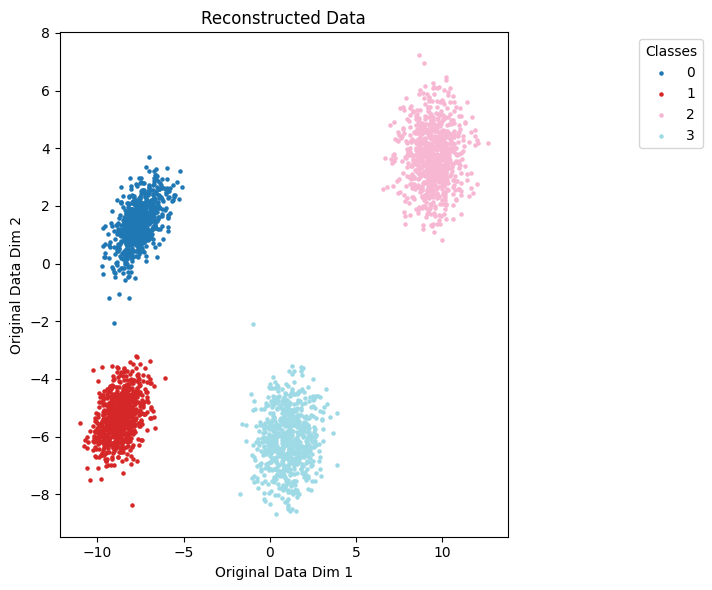

In [28]:
cmap = plt.get_cmap('tab20')
values = np.linspace(0, 1, len(set(labels)))
colours = [cmap(val) for val in values]

# Plot the UMAP results
plt.figure(figsize=(8, 6))
handles = [plt.scatter(val_recons[labels == l, 0], val_recons[labels == l, 1], s=5, c=colours[l]) for l in sorted(set(labels))]
custom_labels = sorted(set(labels))

# Create a legend with custom labels
plt.legend(handles, custom_labels, title="Classes", loc="upper right", bbox_to_anchor=(1.45, 1.0))

plt.title("Reconstructed Data")
plt.xlabel('Original Data Dim 1')
plt.ylabel('Original Data Dim 2')
plt.tight_layout()
plt.savefig(f"{out_dir}/recon-vae-{latent_dim}-{data_name}-{comment}.png")
plt.show()
